In [58]:
# Import the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")
# Load the Mall Customer Segmentation dataset

url = "https://raw.githubusercontent.com/hannazan/mall-customer-segmentation/main/data/Mall_Customers.csv"

df = pd.read_csv(url)

# Display the first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

All libraries imported successfully!
First 5 rows of the dataset:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [59]:
# Explore the dataset

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nGender Distribution:")
print(df["Gender"].value_counts())

Dataset Shape: (200, 5)

Column Names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Rows: 0

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Gender Distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64


In [60]:
# Step 4: Data Preprocessing

# Select the features for customer segmentation
features = df[["Annual Income (k$)", "Spending Score (1-100)"]]

# Check the selected features
print("Selected Features:")
display(features.head())

# Standardize the features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Convert scaled data into a DataFrame
scaled_df = pd.DataFrame(
    scaled_features,
    columns=["Annual Income", "Spending Score"]
)

print("\nScaled Features:")
display(scaled_df.head())

print("\nScaled Data Shape:", scaled_df.shape)

Selected Features:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Scaled Features:


,Annual Income,Spending Score
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Scaled Data Shape: (200, 2)


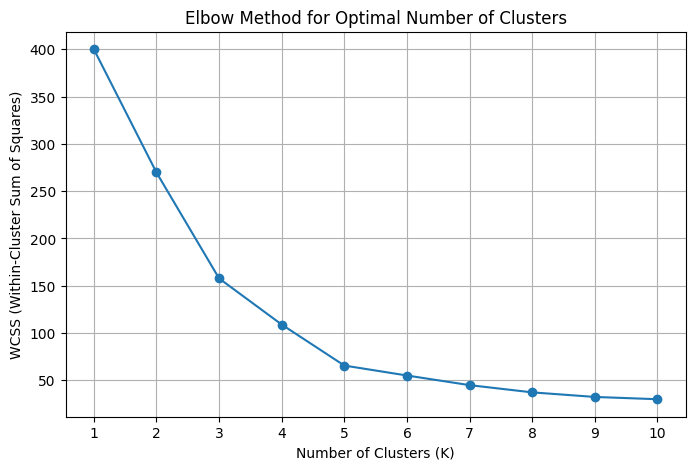

In [61]:
# Step 5: Find the optimal number of clusters using the Elbow Method

wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [62]:
# Step 6: Apply K-Means Clustering

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

# Assign a cluster to each customer
df["Cluster"] = kmeans.fit_predict(scaled_features)

# Calculate Silhouette Score
score = silhouette_score(scaled_features, df["Cluster"])

print("K-Means Clustering Completed!")
print("Number of Clusters:", df["Cluster"].nunique())
print("Silhouette Score:", round(score, 3))

print("\nNumber of Customers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nSample Results:")
display(df.head(10))

K-Means Clustering Completed!
Number of Clusters: 5
Silhouette Score: 0.555

Number of Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Sample Results:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4
5,6,Female,22,17,76,2
6,7,Female,35,18,6,4
7,8,Female,23,18,94,2
8,9,Male,64,19,3,4
9,10,Female,30,19,72,2


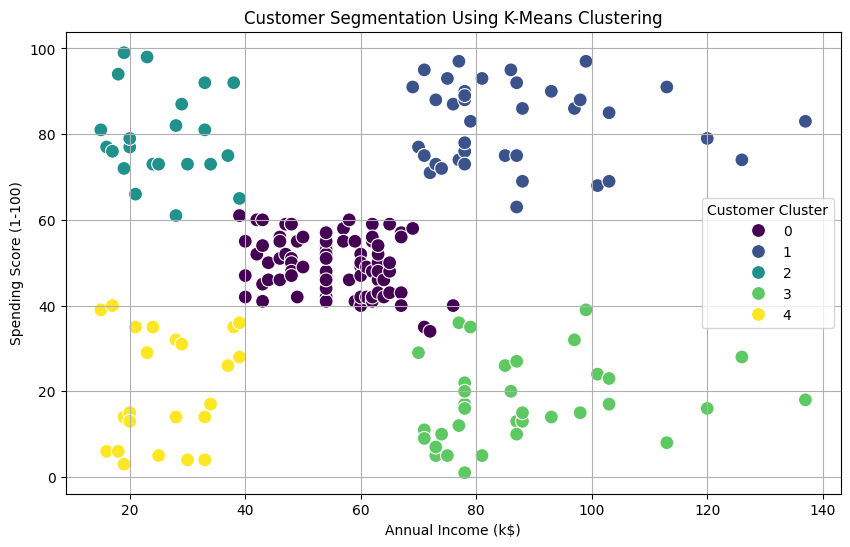

In [63]:
# Step 7: Visualize Customer Clusters

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Customer Segmentation Using K-Means Clustering")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Cluster")
plt.grid(True)
plt.show()

In [64]:
# Step 8: Analyze the Characteristics of Each Cluster

cluster_analysis = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Cluster Analysis:")
display(cluster_analysis)

Customer Cluster Analysis:


,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


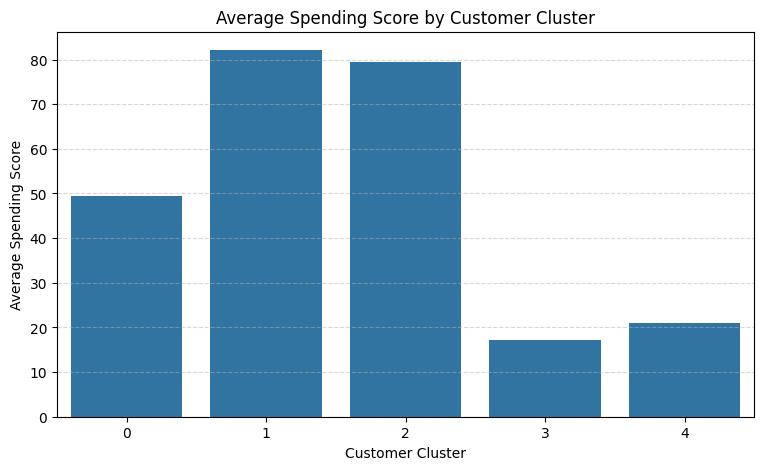

In [65]:
# Step 9: Compare Average Spending Scores Across Clusters

plt.figure(figsize=(9, 5))

sns.barplot(
    x=cluster_analysis.index,
    y=cluster_analysis["Average_Spending_Score"]
)

plt.title("Average Spending Score by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending Score")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()

In [66]:
# Step 10: Evaluate the Clustering Model

from sklearn.metrics import silhouette_score

score = silhouette_score(scaled_features, df["Cluster"])

print("CLUSTERING EVALUATION")
print("---------------------")
print("Number of clusters:", df["Cluster"].nunique())
print("Silhouette Score:", round(score, 3))

print("\nCustomers in Each Cluster:")
print(df["Cluster"].value_counts().sort_index())

# Save the cluster analysis
cluster_analysis.to_csv("cluster_analysis.csv")

# Save the dataset with cluster labels
df.to_csv("mall_customers_clustered.csv", index=False)

print("\nFiles saved successfully!")

CLUSTERING EVALUATION
---------------------
Number of clusters: 5
Silhouette Score: 0.555

Customers in Each Cluster:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Files saved successfully!


In [67]:
from google.colab import files

files.download("cluster_analysis.csv")
files.download("mall_customers_clustered.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>